# 8. Advanced routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/08_routing_advanced.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/08_routing_advanced.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-8.svg" alt="duckOSM notebook manual, chapter 8: Advanced routing" width="100%">

| **You learn** | the graph that all routing calls search; the members of a `Route`; the fastest or the shortest route; the k best routes; many routes in parallel; a travel time matrix; isochrones; accessibility |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[widget,viz,graph]` (the install cell installs them) |
| **Next** | [9. Street network analysis](09_analysis.md): the numbers of OSMnx, junctions, components and points |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,graph] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## One graph for all routing calls

[7. Routing](07_routing.md) finds one route from A to B. This chapter uses the other calls of the module
`duckosm.routing`. They answer larger questions: the next best routes, a route for each of 100 pairs, the travel time
between all pairs of 100 places, the area that you reach in 10 minutes on foot, and the nearest stop from each street.

All these calls search **the same graph**: the turn graph of the mode (the table `<mode>.edge_graph`). A node is an
edge of the road network, and an arc is a legal turn ([7. Routing](07_routing.md), section "How duckOSM finds a
route"). The search runs in Rust. Each call opens the database file, reads the graph once, and searches it with
Dijkstra's algorithm.

| Call | Question | Algorithm |
|---|---|---|
| `route(a, b)` | the best route from A to B | bidirectional Dijkstra |
| `routes(origins, destinations)` | the best route for each pair, in parallel | bidirectional Dijkstra, the pairs in parallel |
| `k_shortest_paths(a, b, k)` | the `k` best routes from A to B | Yen's algorithm |
| `matrix(origins, destinations)` | the time from each origin to each destination | one Dijkstra search from each origin |
| `isochrones(origins, minutes)` | the area reached within each time | one Dijkstra search, stopped at the largest time |
| `accessibility(origins, targets, minutes)` | the targets reached from each origin, and the nearest | `matrix` with a time limit |

Each call is a function of the module, `duckosm.routing.matrix(net.driving, ...)`, and also a method of a mode view,
`net.driving.matrix(...)`. This chapter uses the methods.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> All routing calls search the same turn graph, with the same turn rules. So a cell of the matrix is the time of `route` for the same pair, the first of the k best routes is `route`, and an isochrone holds the edges whose matrix time is in the limit.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter
opens that file with `duckosm.open`: it builds nothing. The routes use the driving network and the walking network.
The start and the end of each call are places, as in chapter 7: an edge id, a `(lon, lat)` point or a place name. An
edge id is the fastest place, because it needs no search for the nearest edge.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                    # the card of the network

Network('monaco.duckdb', 52.7 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

## The Route object

`route` gives a `Route`, or `None` when no route connects the two places. In a notebook a `Route` shows a card with
the number of edges, the length and the time. Here the two places are street names.

In [3]:
r = net.driving.route("Boulevard Albert 1er", "Avenue Princesse Grace")    # from street to street, by car
r                                                                        # the card: edges, length, time

edges,33
length,"1,350 m"
time,2.0 min


The route by car from Boulevard Albert 1er to Avenue Princesse Grace has 33 edges, 1,350 m and 122 s (2.0 minutes). Each name became a point (with `geocode`), so the route starts and ends at the points on the two streets, not at the ends of whole edges.

### What a Route stores, and what it reads from the file

A `Route` is small. It keeps only the result of the search, and two links to the network:

| Stored in the Route | In this example |
|---|---|
| the edge ids, in the order of the route (`r["edges"]`) | 33 edge ids |
| the time and the length (`r["time_s"]`, `r["length_m"]`) | 122 s, 1,350 m |
| the start and the end (`r["start"]`, `r["end"]`): the point, the nearest road point, its `edge_id`, how far along the edge (`fraction`), and the walk to the road (`access_m`, `access_s`) | the end is 12 m from its road |
| the steps of the search (`r["path"]`) | 33 steps |
| the network file, and the mode (hidden: `r._db`, `r._mode`) | `monaco.duckdb`, `driving` |

The `Route` does not store the columns of the edges. When you ask for them, it opens its network file again and
reads the 33 edges with a query (`SELECT ... FROM driving.edges WHERE edge_id IN (...)`), in the order of the route.

| Member | Gives | From |
|---|---|---|
| `r.edge_ids` | the edge ids, in the order of the route | the Route |
| `r.length_m`, `r.time_s` | the sums of `length_m` and `cost_s` of the edges | the Route |
| `r.edges` | a GeoDataFrame of the edges in the order of the route: `seq`, `edge_id` and all the columns of `<mode>.edges` (`name`, `highway` ...) | the file, at each call |
| `r.geometry` | one shapely line (a `MultiLineString` where the edges do not join) | the file, at each call |
| `r.directions()` | the turn-by-turn steps | the file, at each call |
| `r.map()` | the route on the roadstyle map of the network | the file, at each call |

So you can keep thousands of routes in memory, and `r.edges` gives all the columns of the edges table: you can count
the road classes of a route or sum the length of its tunnels.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> `r.edges`, `r.geometry`, `r.directions()` and `r.map()` need the network file. If you move or delete `monaco.duckdb`, they fail. `r["edges"]`, `r.time_s` and `r.length_m` still work.

In [4]:
print(len(r.edge_ids), "edges,", round(r.length_m), "m,", round(r.time_s), "s")    # the sums
r.edges[["seq", "edge_id", "name", "highway", "length_m", "cost_s"]].head()          # the first edges, in order

33 edges, 1350 m, 122 s


,seq,edge_id,name,highway,length_m,cost_s
0,0,2478527519211067132,Boulevard Albert 1er,service,105.471190,18.984814
1,1,570930183709886355,Boulevard Albert 1er,service,25.228455,4.541122
2,2,2037729375342856465,Boulevard Albert 1er,secondary,34.672100,2.496391
3,3,4052179255342490971,Rond-Point Sainte-Dévote,secondary,3.045039,0.219243
4,4,8315515182314187580,Avenue John F. Kennedy,secondary,25.473068,1.834061


In [5]:
r.edges.groupby("highway").length_m.sum().round().sort_values(ascending=False)    # the metres of each road class

highway
secondary    1043.0
tertiary      280.0
service       131.0
Name: length_m, dtype: float64

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The first five edges go along Boulevard Albert 1er, through the roundabout Rond-Point Sainte-Dévote, to Avenue John F. Kennedy. The route has 1,043 m of secondary roads, 280 m of tertiary roads and 131 m of service roads. These sums count whole edges, so they are a little more than the 1,350 m of the card.

### The line and the steps

`r.geometry` joins the lines of the edges into one line. Use it to measure the route, to draw it, or to find the
places near it. `r.directions()` gives the turn-by-turn steps, as [7. Routing](07_routing.md) shows.

In [6]:
print(r.geometry.geom_type, len(r.geometry.coords), "points")    # one line
[step["text"] for step in r.directions()][:5]                   # the first turn-by-turn steps

LineString 83 points


['Head north on Boulevard Albert 1er',
 'At the roundabout, take the 1st exit onto Avenue John F. Kennedy',
 'Continue onto Boulevard Louis II',
 'At the roundabout, take the 2nd exit onto Avenue Princesse Grace',
 'Arrive at your destination']

### A Route is also a dict

A `Route` is a Python `dict` too, with the keys of the table above: `edges`, `time_s`, `length_m`, `start`, `end`
and `path`. The code that used the dict of older duckOSM versions works without a change, and `net.map(routes=r)` takes a
`Route`.

In [7]:
sorted(r.keys()), r["edges"][:3]    # the keys of the dict, and the first edge ids

(['edges', 'end', 'length_m', 'path', 'start', 'time_s'],
 [2478527519211067132, 570930183709886355, 2037729375342856465])

## The fastest or the shortest: `weight`

`weight="time"` (the default) gives the fastest route: the sum of `cost_s`. `weight="length"` gives the shortest
route: the sum of `length_m`. All calls of this chapter, except `isochrones` and `accessibility`, take `weight`.

In [8]:
import pandas as pd

ids = net.driving.edges().edge_id.sample(200, random_state=1).tolist()   # 200 driving edges, chosen at random
fast = net.driving.route(ids[0], ids[6])                                  # the fastest route between two of them
short = net.driving.route(ids[0], ids[6], weight="length")                # the shortest route
pd.DataFrame({"fastest": [fast.length_m, fast.time_s], "shortest": [short.length_m, short.time_s]},
             index=["length_m", "time_s"]).round()                              # the two routes side by side

,fastest,shortest
length_m,2049.0,1784.0
time_s,142.0,186.0


Between these two edges the fastest route is 2,049 m and 142 s. The shortest route is 1,784 m, 265 m shorter, but it takes 186 s, 44 s more: it uses slower streets. In a city of steep, narrow streets the two weights often give different routes.

## The k best routes: `k_shortest_paths`

`k_shortest_paths(a, b, k=3)` gives the `k` best routes from A to B, the best first. It uses Yen's algorithm on the
same graph and turn rules as `route`. A route uses each edge one time only. The first route is the route of `route`
for the same two edges. When the graph has fewer than `k` routes, the list is shorter.

Use the next best routes to show a driver two or three choices, or to spread traffic in a simulation over more than
one road.

In [9]:
a, b = r.edge_ids[0], r.edge_ids[-1]                       # the first and the last edge of the route
best = net.driving.k_shortest_paths(a, b, k=3)              # the 3 fastest routes
[(round(x.time_s), round(x.length_m), len(x.edge_ids)) for x in best]    # seconds, metres and edges of each

[(126, 1453, 33), (127, 1459, 35), (127, 1464, 35)]

In [10]:
best[0].edge_ids == net.driving.route(a, b).edge_ids    # the first route is the route of route()

True

The three routes take 126 s, 127 s and 127 s, with 1,453 m, 1,459 m and 1,464 m. The second and the third route have 35 edges, two more than the first. The first route is the same as the route of `route` for the two edges (`True`). Each route takes as long as the route before it, or longer.

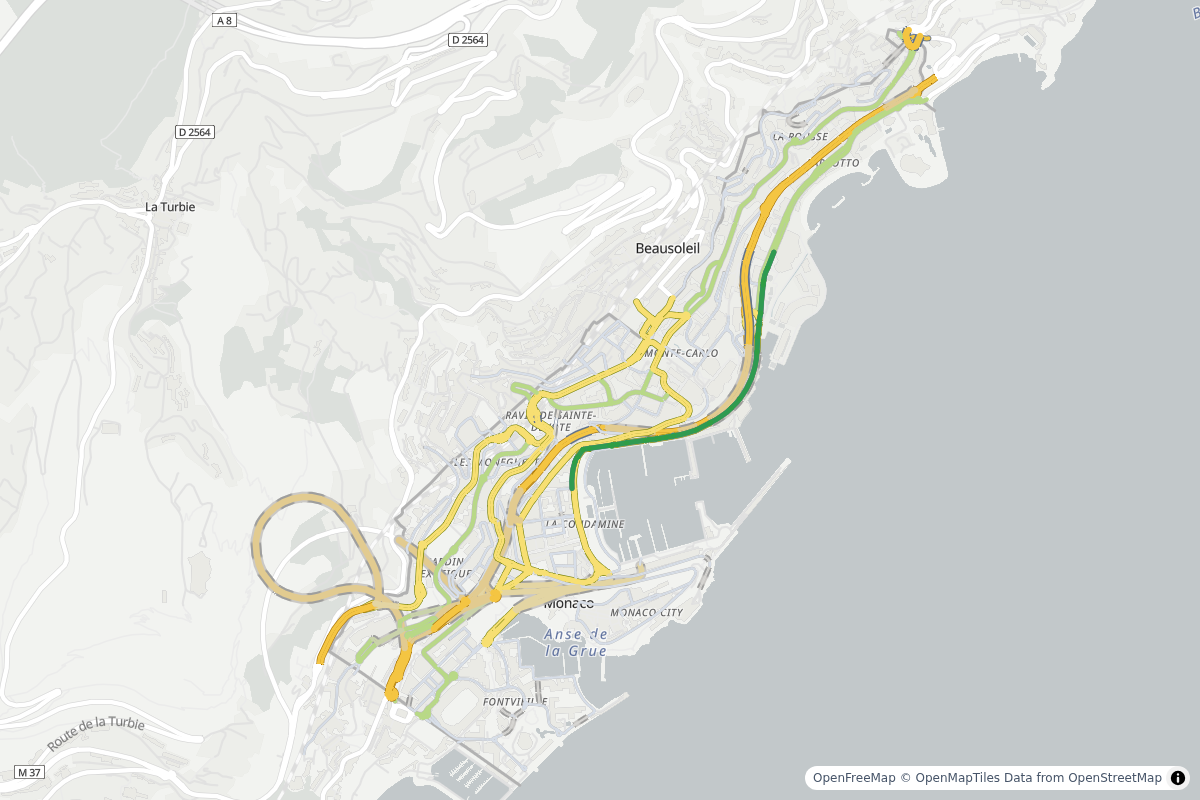

In [11]:
net.map("driving", routes={f"route {i + 1}": x for i, x in enumerate(best)})    # the 3 routes on the map

## Many routes in parallel: `routes`

`routes(origins, destinations)` takes two lists of the same length. It finds the route from each origin to the
destination at the same place in the other list, as Python's `zip` pairs them. The pairs run in parallel on all
the cores of the computer. The result is a list of `Route`, with `None` for a pair that no route connects.

Here the places are the 200 random driving edges of the section above: 100 origins and 100 destinations.

In [12]:
many = net.driving.routes(ids[:100], ids[100:])    # 100 routes: ids[0] to ids[100], ids[1] to ids[101] ...
sum(x is not None for x in many)                    # the routes found

90

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> 90 of the 100 pairs have a route. The other 10 pairs have `None`: one of their edges cannot reach the other, for example an edge in a garage that only leaves the network, or an edge that is not in the graph of the mode (see `routed_graph` below). The histogram shows the time of the 90 routes.

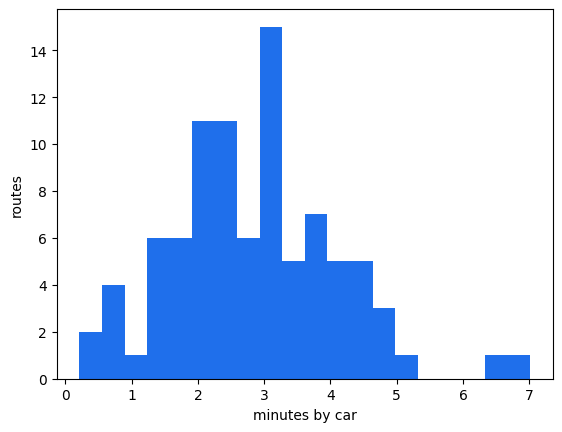

In [13]:
import matplotlib.pyplot as plt

times = [x.time_s / 60 for x in many if x is not None]        # the time of each route in minutes
plt.hist(times, bins=20, color="#1f6feb")                     # a histogram
plt.xlabel("minutes by car"); plt.ylabel("routes"); plt.show()    # the labels

Most routes take 1.5 to 4.5 minutes by car, and the longest take about 7 minutes.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> The two lists must have the same length. `routes([e1, e2], [e3])` stops with the error `2 origins and 1 destinations: give the same number`. For all pairs of two lists, use `matrix`.

## A travel time matrix: `matrix`

`matrix(origins, destinations)` gives the travel time from each origin to each destination, as a pandas DataFrame:
one row for each origin, one column for each destination. A cell is in seconds (`weight="length"`: in metres). Without
`destinations`, the destinations are the origins.

The matrix does not find one route for each cell. It runs one Dijkstra search from each origin, and this search
reaches all destinations. The origins run in parallel. So a matrix of 100 × 100 places costs about as much as 100
routes.

| Argument | Default | What it does |
|---|---|---|
| `origins` | | the places of the rows |
| `destinations` | `None` | the places of the columns (`None`: the origins) |
| `weight` | `"time"` | `"length"`: metres, not seconds |
| `max_cost` | `None` | the largest cell: each search stops there, and a larger cell is `NaN` |

A cell is `NaN` when no route connects the pair, when the cost is more than `max_cost`, or when the edge is not in the
graph of the mode (for example an edge for buses only).

In [14]:
m = net.driving.matrix(ids[:100])                             # 100 x 100 travel times in seconds
m.iloc[:5, :5].round()                                        # the first cells

,3050652600567400442,4119412884669195015,8277540089478770184,1389707648760686556,7815454498997486282
3050652600567400442,6.0,96.0,126.0,169.0,60.0
4119412884669195015,121.0,0.0,151.0,228.0,85.0
8277540089478770184,165.0,165.0,13.0,266.0,127.0
1389707648760686556,203.0,232.0,263.0,3.0,196.0
7815454498997486282,111.0,112.0,104.0,213.0,1.0


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The rows and the columns have the edge ids as their labels. A cell on the diagonal is the time of the edge itself: from its start to its end (6 s for the first edge). The matrix is not symmetric: 96 s from the first edge to the second, but 121 s back, because of the one-way streets.

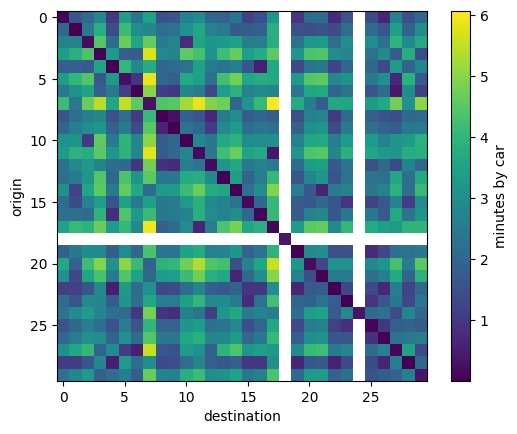

In [15]:
plt.imshow(m.iloc[:30, :30] / 60, cmap="viridis")           # a heat map of 30 x 30 cells, in minutes
plt.colorbar(label="minutes by car")                          # the scale
plt.xlabel("destination"); plt.ylabel("origin"); plt.show()   # the labels

### A cell equals the route

A cell is the time of `route` for the same two edges: from the start of the origin edge to the end of the destination
edge. The tests of duckOSM check this rule for each cell.

In [16]:
round(m.iloc[0, 1]) == round(net.driving.route(ids[0], ids[1]).time_s)    # a cell equals the route

True

### A time limit: `max_cost`

`max_cost` stops each search at that cost. A cell above it is `NaN`. Use it for a large matrix when only the near
places count: the search then reads a small part of the graph.

In [17]:
near = net.driving.matrix(ids[:100], max_cost=120)    # only the cells of 2 minutes or less
print(f"{near.notna().to_numpy().mean():.0%} of the cells are 2 minutes or less")    # the share of cells with a value

27% of the cells are 2 minutes or less


With `max_cost=120`, 27 % of the cells have a value. The other cells are `NaN`, because they cost more than 2 minutes or no route connects them.

### Points and names as places

The origins and the destinations can be points and names too. The rows and the columns then have the numbers
`0, 1, 2 ...`. When all places are edge ids or names, the rows and the columns have the places as their labels.

In [18]:
places = ["Boulevard Albert 1er", "Avenue Princesse Grace", "Boulevard de Suisse"]    # three streets
(net.driving.matrix(places, weight="length") / 1000).round(2)                          # the distances in km

,Boulevard Albert 1er,Avenue Princesse Grace,Boulevard de Suisse
Boulevard Albert 1er,0.11,1.88,1.46
Avenue Princesse Grace,2.08,0.12,1.76
Boulevard de Suisse,1.66,2.15,0.09


The rows and the columns have the three names. With `weight="length"` the cells are metres, and the code divides them by 1,000. From Boulevard Albert 1er to Avenue Princesse Grace is 1.88 km, and the way back is 2.08 km. The diagonal is the length of the edge of the name (0.09 to 0.12 km).

## Isochrones: `isochrones`

### What an isochrone is

An **isochrone** answers one question: how far can I go from here in 10 minutes? It is the area that you reach from a
place within a time, on the roads of one mode. It is not a circle, because the roads, the hills and the sea limit
where you can go.

### How duckOSM makes it

1. It searches the roads from the start place, up to the largest time.
2. It keeps each edge that you reach to its end within the time.
3. It draws a band of 25 m around each kept edge, and joins the bands into one polygon.

So a park or a block with no road stays out of the polygon.

### The call

`net.walking.isochrones(origins, minutes)` gives one polygon for each start place and each time.

| Argument | Default | What it does |
|---|---|---|
| `origins` | | a list of start places: `(lon, lat)` points, edge ids or place names |
| `minutes` | `(5, 10, 15)` | the times: one number or a list |
| `buffer_m` | `25.0` | the width of the band around each reached edge, in metres |

Here the start is the casino square, on foot, for 5, 10 and 15 minutes.

In [19]:
casino = (7.4280, 43.7393)                                       # Place du Casino (lon, lat)
iso = net.walking.isochrones([casino], minutes=[5, 10, 15])      # one polygon for each time
iso[["minutes", "n_edges", "area_km2"]]                          # the reached edges and the area of each polygon

,minutes,n_edges,area_km2
0,5.0,1525,0.238
1,10.0,3483,0.645
2,15.0,5983,1.148


Each row is one polygon. From the casino square, 1,525 walking edges are within 5 minutes, 3,483 within 10
minutes and 5,983 within 15 minutes. The areas are 0.24 km², 0.65 km² and 1.15 km².

### Draw the isochrones

The cell draws the walking roads in gray, then the three polygons over them. It draws the largest polygon first,
so the smaller ones stay on top of it.

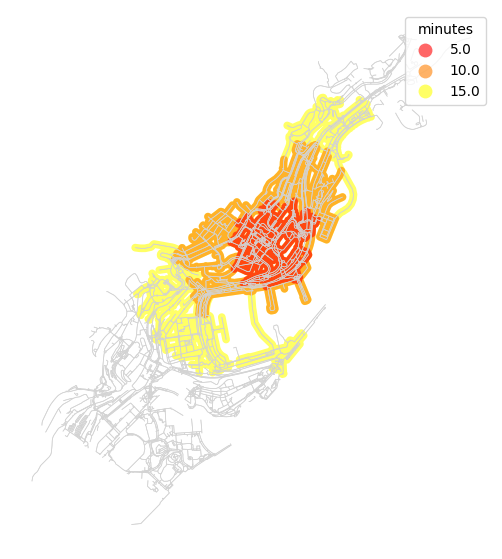

In [20]:
fig, ax = plt.subplots(figsize=(7, 7))                                          # one picture
net.walking.edges().plot(ax=ax, color="lightgray", linewidth=0.5)               # the walking roads, in gray
iso[::-1].plot(ax=ax, column="minutes", categorical=True, cmap="autumn", alpha=0.6,
               legend=True, legend_kwds={"title": "minutes"})                  # the polygons: 15, 10, then 5 minutes
ax.set_axis_off()                                                               # no degrees on the sides
plt.show()

Each polygon follows the streets and the steps, not a circle: the hills and the sea limit the walk.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The walking speed comes from `cost_s` of the walking edges. For more than one start place, give a list: each place gets its own polygons, with its place in the column `origin`.

## Accessibility: `accessibility`

### What accessibility is

Accessibility answers two questions for each place where people start, for example each street where people live:

- How many targets can I reach within 5 or 10 minutes?
- Which target is the nearest, and how far is it?

The targets are the places that people go to: bus stops, schools, shops, pharmacies or parks.

### How duckOSM finds it

1. It searches the roads from each start place, up to the largest time (one search for each start, in parallel).
2. It counts the targets that it reaches within each time.
3. It keeps the nearest target and its time.

### The call

`net.walking.accessibility(origins, targets, minutes)` gives a DataFrame with one row for each start place.

| Argument | What it is |
|---|---|
| `origins` | the start places: edge ids, `(lon, lat)` points or names, in a list or a dict `{name: place}` |
| `targets` | the places to reach, in the same forms. With a dict, the names appear in the result |
| `minutes` | the times: one number or a list |

| Column of the result | What it is |
|---|---|
| `n_5min`, `n_10min` ... | the number of targets within each time |
| `nearest` | the nearest target: its name in the dict |
| `nearest_s` | the time to the nearest target, in seconds |

A start place with no target within the largest time has `None` in `nearest` and `NaN` in `nearest_s`.

Here the start places are all the walking edges of Monaco, and the targets are three places with names.

In [21]:
targets = {"Fontvieille": (7.4155, 43.7285),                     # three targets, with their names
           "the port": (7.4246, 43.7384),
           "Larvotto": (7.4335, 43.7468)}
homes = net.walking.edges().edge_id                               # each walking edge is a start place
acc = net.walking.accessibility(homes, targets, minutes=[5, 10])  # the targets within 5 and 10 minutes
acc.head()                                                        # one row for each start edge

,n_5min,n_10min,nearest,nearest_s
414242052250797,0,1,Larvotto,536.303398
901203926603589,1,1,Fontvieille,279.352130
2214154189574909,0,1,Fontvieille,316.343565
2362608876371269,0,0,None,NaN
2686560736896665,0,2,Larvotto,484.165528


Each row is one walking edge: the number of targets within 5 and 10 minutes, the nearest target and its time
in seconds. The fourth edge reaches no target within 10 minutes, so its `nearest` is `None`.

### Count the results

`value_counts` counts the edges for each number of targets.

In [22]:
acc.n_10min.value_counts().sort_index()      # how many edges reach 0, 1 or 2 targets within 10 minutes

n_10min
0    3416
1    8194
2     328
Name: count, dtype: int64

In [23]:
acc.nearest.value_counts(dropna=False)       # how many edges have each target as the nearest

nearest
Fontvieille    3517
None           3416
the port       3039
Larvotto       1966
Name: count, dtype: int64

Within 10 minutes, 8,194 edges reach one target, 328 edges reach two, and 3,416 edges reach none. Fontvieille is
the nearest target of 3,517 edges, the port of 3,039 and Larvotto of 1,966.

### Draw it on the map

The map colors each walking edge by the minutes to its nearest target. An edge with no target within 10 minutes
stays gray.

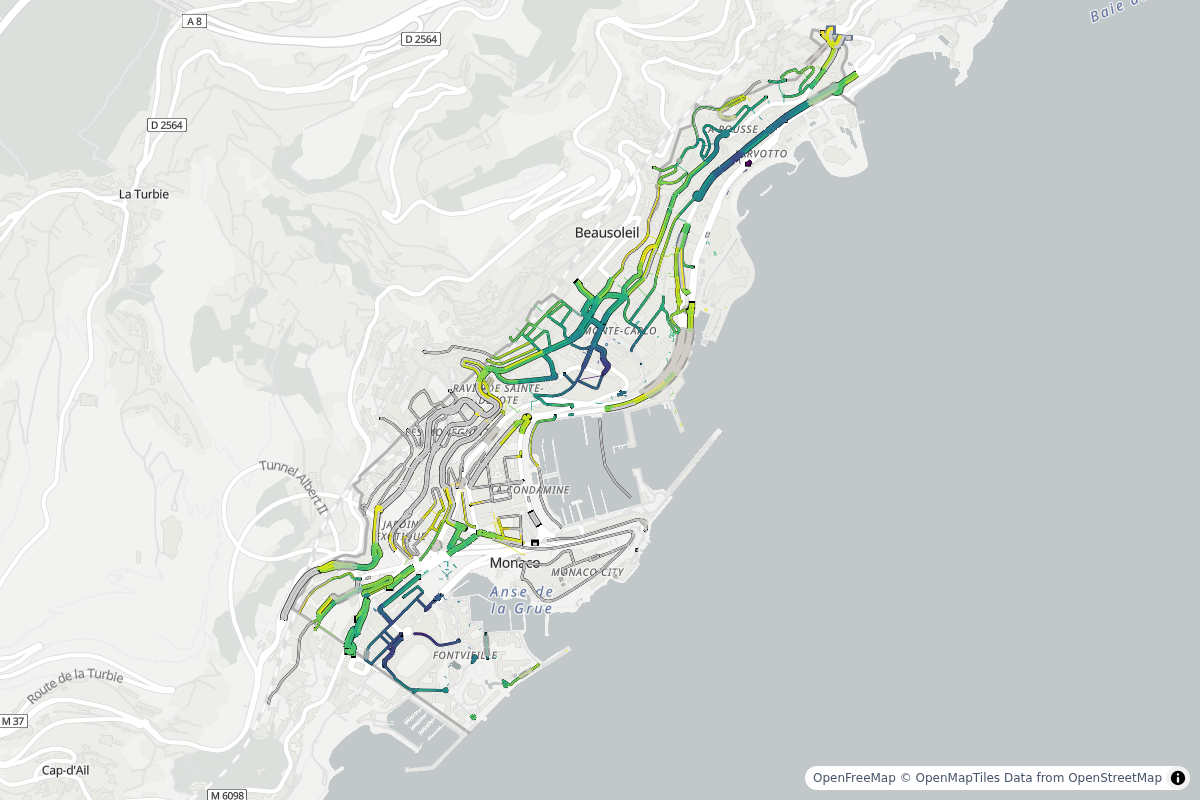

In [24]:
net.map("walking", color_by=acc["nearest_s"] / 60, cmap="viridis")    # the minutes to the nearest target

The dark edges are near a target, and the yellow edges are about 9 minutes away.

## The graph of all calls: `routed_graph`

### The turns that a mode can use

All the routing calls of this chapter search one graph: the turns of the mode, in the table `<mode>.edge_graph`
(chapter 7). But not every row of that table is for the mode. The column `uses` says who can make each turn. The
cell counts the rows of `driving.edge_graph` by `uses`.

In [25]:
net.sql("""SELECT uses, count(*) AS turns
           FROM driving.edge_graph GROUP BY uses ORDER BY turns DESC""")    # who can make each turn

,uses,turns
0,car,5082
1,pedestrian,1149
2,private,472
3,bus,51


The table has 6,754 turns. A car can make 5,082 of them (`car`). The others go onto or from an edge that is not
open to all cars: a pedestrian street (`pedestrian`), a private road (`private`) or a bus lane (`bus`). A car route
uses only the `car` turns.

### `routed_graph`: those turns, for your own SQL

`duckosm.routing.routed_graph(view)` gives the turns that the mode routes on. It gives them as a piece of SQL text, so
you can put it into your own query, in place of a table name.

In [26]:
g = duckosm.routing.routed_graph(net.driving)     # the turns that a car route uses, as SQL text
print(g)

(SELECT * FROM driving.edge_graph WHERE uses = 'car')


The text selects the rows of `driving.edge_graph` with `uses = 'car'`. The next cell puts it into a query, after
`FROM`, and counts the turns and the edges where a car route can start: an edge with at least one turn to a next
edge.

In [27]:
net.sql(f"SELECT count(*) AS turns, count(DISTINCT from_edge) AS start_edges FROM {g}")

,turns,start_edges
0,5082,2814


A car can make 5,082 turns, and a car route can start on 2,814 edges.

### The edges where a route cannot start

Monaco has 2,840 driving edges, so 26 edges have no turn to a next edge. The cell finds them and counts their road
classes.

In [28]:
net.sql(f"""SELECT highway, count(*) AS edges FROM driving.edges
           WHERE edge_id NOT IN (SELECT from_edge FROM {g})
           GROUP BY highway ORDER BY edges DESC""")                 # the 26 edges with no turn out

,highway,edges
0,service,13
1,residential,8
2,primary,3
3,primary_link,1
4,tertiary,1


13 of the 26 edges are service roads and 8 are residential streets: the end of a dead-end street, or a garage
exit. The 5 main roads end at the boundary of the area: the road goes on in OSM, but the cut file stops there. A route
cannot leave such an edge, so `route` gives `None` for a route that starts on it, as in "Many routes in parallel"
above.

## Try it yourself

**1.** Find the three best walking routes from the casino square to the port, and compare their times.

<details><summary>Show the answer</summary>

```python
walk = net.walking.k_shortest_paths((7.4280, 43.7393), (7.4246, 43.7384), k=3)
[round(x.time_s / 60, 1) for x in walk]      # minutes of each route
```
</details>

**2.** Make a matrix of walking distances in metres between the three targets of the accessibility section.

<details><summary>Show the answer</summary>

```python
net.walking.matrix(list(targets.values()), weight="length").round()     # rows and columns 0, 1, 2
```
</details>

**3.** Draw the 5 and 10 minute isochrones by car from the port, with a buffer of 40 m.

<details><summary>Show the answer</summary>

```python
iso_car = net.driving.isochrones([(7.4246, 43.7384)], minutes=[5, 10], buffer_m=40)
iso_car.iloc[::-1].plot(column="minutes", categorical=True, legend=True)
```
</details>

**4.** Find the walking edges that have no target within 10 minutes, and draw them on the map.

<details><summary>Show the answer</summary>

```python
far = acc[acc.n_10min == 0].index           # the origin edge ids
net.map("walking", highlight=list(far))
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| `Route` | the result of a route: the edges, the length, the time, the line, the steps and a map |
| weight | what a route makes smallest: `"time"` (`cost_s`) or `"length"` (`length_m`) |
| Dijkstra's algorithm | a search that finds the cheapest route from one place to all other places |
| Yen's algorithm | a search that finds the `k` best routes that use no edge two times |
| matrix | a table of the travel times (or distances) from each origin to each destination |
| isochrone | the area that you reach from a place within a time |
| accessibility | the number of targets that you reach from a place within a time, and the nearest one |

## Summary

| Call | Does |
|---|---|
| `net.driving.route(a, b, weight=...)` | the best route, a `Route` (or `None`) |
| `r.edge_ids`, `r.edges`, `r.length_m`, `r.time_s` | the edges and the sums of a route |
| `r.geometry`, `r.directions()`, `r.map()` | the line, the steps and the map of a route |
| `net.driving.k_shortest_paths(a, b, k=3)` | the `k` best routes, the best first |
| `net.driving.routes(origins, destinations)` | a route for each pair (`zip`), in parallel |
| `net.driving.matrix(origins, destinations, max_cost=...)` | a travel time (or distance) matrix, a DataFrame |
| `net.walking.isochrones(origins, minutes, buffer_m=...)` | the polygons reached within each time |
| `net.walking.accessibility(origins, targets, minutes)` | the targets reached from each origin, and the nearest |
| `duckosm.routing.routed_graph(view)` | the turns that the mode routes on, as SQL text for your own query |

The reference: [duckosm.routing](../reference/sdk/routing.md). **Next:** [9. Street network analysis](09_analysis.md), the numbers of OSMnx, junctions, components and points.